### Introduction

The goal of this notebook is to perform EDA analysis on our variables that predict sunset quality. I am currently working in a self labled data set that targets rating which will be predicted using the variables, `date`, `sunset_time`, `rating_source`, `cloud_cover`,
       `cloud_cover_low`, `cloud_cover_mid`, `cloud_cover_high`, `humidity`, `visibility`, `temperature`, `wind_speed`, `created_at`.


In [ ]:
import sqlite3
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np

In [ ]:
conn = sqlite3.connect(r"C:\Users\ed4er\sunset-predictor\sunset.db") #connect to db
df = pd.read_sql_query("SELECT * FROM sunset_ratings", conn) #create dataframe out of sql query
df1 = pd.read_sql_query("SELECT * FROM weather_logs", conn)
conn.close()

In [ ]:
df.columns

Index(['id', 'date', 'sunset_time', 'rating', 'rating_source', 'cloud_cover',
       'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'humidity',
       'visibility', 'temperature', 'wind_speed', 'created_at'],
      dtype='str')

In [4]:
df1.head()

,id,timestamp,sunset_time,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,humidity,visibility,temperature,wind_speed
0,1,2026-02-15T16:00:22.497314,2026-02-15T17:48:47.493896-08:00,84.0,84.0,76.0,0.0,88.0,15000.0,12.5,12.6
1,2,2026-02-16T11:11:54.683443,2026-02-16T17:49:51.830313-08:00,100.0,100.0,100.0,0.0,91.0,13100.0,8.7,6.0
2,4,2026-02-17T12:09:04.003469,2026-02-17T17:50:55.862826-08:00,98.0,66.0,98.0,0.0,84.0,16800.0,7.1,18.1
3,5,2026-02-18T12:59:26.320789,2026-02-18T17:51:59.584910-08:00,100.0,8.0,100.0,0.0,75.0,22000.0,7.4,8.7
4,6,2026-02-19T14:48:59.680660,2026-02-19T17:53:02.991241-08:00,0.0,0.0,0.0,0.0,73.0,22800.0,7.0,16.9


In [5]:
df1["timestamp"].duplicated().sum()

np.int64(0)

In [6]:
df["date"].duplicated().sum()

df.head()

,id,date,sunset_time,rating,rating_source,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,humidity,visibility,temperature,wind_speed,created_at
0,1,2026-02-16,2025-02-16T17:50:07.378847-08:00,1,in_person,100.0,100.0,0.0,98.0,89.0,NaN,12.2,5.8,2026-02-16T18:57:04.294634
1,2,2017-10-23,2017-10-23T18:20:54.751575-07:00,6,photo,0.0,0.0,0.0,0.0,71.0,NaN,19.5,9.7,2026-02-16T19:19:08.850832
2,3,2018-12-29,2018-12-29T16:59:05.629837-08:00,8,photo,9.0,0.0,0.0,9.0,63.0,NaN,12.1,4.9,2026-02-16T19:19:54.291820
3,4,2026-02-17,2026-02-17T17:50:55.862826-08:00,1,in_person,100.0,52.0,100.0,97.0,82.0,NaN,7.3,29.8,2026-02-17T19:07:28.217976
4,5,2026-02-18,2026-02-18T17:51:59.584910-08:00,1,in_person,100.0,31.0,100.0,0.0,75.0,NaN,8.8,10.4,2026-02-19T07:23:42.483405


In [7]:
df1['date'] = pd.to_datetime(df1['timestamp']).dt.date

df1.head()

,id,timestamp,sunset_time,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,humidity,visibility,temperature,wind_speed,date
0,1,2026-02-15T16:00:22.497314,2026-02-15T17:48:47.493896-08:00,84.0,84.0,76.0,0.0,88.0,15000.0,12.5,12.6,2026-02-15
1,2,2026-02-16T11:11:54.683443,2026-02-16T17:49:51.830313-08:00,100.0,100.0,100.0,0.0,91.0,13100.0,8.7,6.0,2026-02-16
2,4,2026-02-17T12:09:04.003469,2026-02-17T17:50:55.862826-08:00,98.0,66.0,98.0,0.0,84.0,16800.0,7.1,18.1,2026-02-17
3,5,2026-02-18T12:59:26.320789,2026-02-18T17:51:59.584910-08:00,100.0,8.0,100.0,0.0,75.0,22000.0,7.4,8.7,2026-02-18
4,6,2026-02-19T14:48:59.680660,2026-02-19T17:53:02.991241-08:00,0.0,0.0,0.0,0.0,73.0,22800.0,7.0,16.9,2026-02-19


In [8]:
df1.duplicated().sum()

np.int64(0)

In [9]:
df.isna().sum()

id                   0
date                 0
sunset_time          0
rating               0
rating_source        0
cloud_cover          0
cloud_cover_low      0
cloud_cover_mid      0
cloud_cover_high     0
humidity             0
visibility          25
temperature          0
wind_speed           0
created_at           0
dtype: int64

In [10]:
print(df['rating_source'].value_counts())

rating_source
in_person    24
photo         5
Name: count, dtype: int64


<Axes: xlabel='rating'>

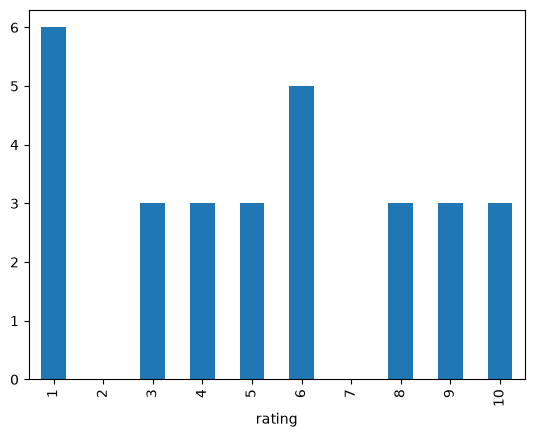

In [11]:
df["rating"].value_counts().reindex(range(1, 11), fill_value=0).sort_index().plot(kind="bar")

In [13]:
df.groupby("rating_source")["rating"].agg(["count", "mean"])

,count,mean
rating_source,,
in_person,25,4.48
photo,5,8.40


In [22]:
RMSE = ((df['rating']-df['rating'].mean())**2).mean()**0.5

RMSE


np.float64(3.063041335376038)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error



In [ ]:
X = df[['cloud_cover',
       'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'humidity', 'visibility', 'temperature', 'wind_speed']]

X

,cloud_cover_low,cloud_cover_high
0,100.0,98.0
1,0.0,0.0
2,0.0,9.0
3,52.0,97.0
4,31.0,0.0
5,16.0,100.0
6,0.0,12.0
7,0.0,0.0
8,60.0,77.0
9,71.0,90.0


In [16]:
X = df[['cloud_cover_low',  'cloud_cover_high']]

y = df['rating']

model = LinearRegression()

model.fit(X,y)


single = X.iloc[[30]]

# 4. Predict safely
prediction = model.predict(single)
print("Prediction:", prediction[0])


Prediction: 3.543292040885663


In [17]:
predicts = model.predict(X)


RMSE = ((df['rating']-predicts)**2).mean()**0.5

print(RMSE)

print(predicts)

2.6534716680919526
[2.68850931 5.66529047 5.81555914 4.88607202 4.23524805 6.596856
 5.8656487  5.66529047 4.18309842 3.89271877 5.61916007 5.66529047
 4.18911765 5.66529047 7.33494241 5.61916007 5.66529047 7.06693821
 6.4579452  5.66529047 5.66529047 5.66529047 2.94359683 1.37516321
 3.96552407 7.08449462 5.66529047 5.61916007 3.22037924 1.97485842
 3.54329204 4.83494326]


In [18]:
df['rating'].mean()


B = df['rating'].mean() - model.coef_[0]*df['cloud_cover_low'].mean() - model.coef_[1]*df['cloud_cover_high'].mean()

B

np.float64(5.665290469724874)

In [19]:
print("Model expects:", model.n_features_in_, "features")
print("Your single observation has:", single.shape[1], "features")

# 2. Check column names (if using pandas DataFrames)
if hasattr(model, "feature_names_in_"):
    print("\nModel columns:", list(model.feature_names_in_))
    print("Single row columns:", list(single.columns))


Model expects: 2 features
Your single observation has: 2 features

Model columns: ['cloud_cover_low', 'cloud_cover_high']
Single row columns: ['cloud_cover_low', 'cloud_cover_high']


(array([4., 7., 6., 5., 2., 5., 1., 0., 1., 1.]),
 array([-3.88607202, -2.73498114, -1.58389026, -0.43279938,  0.7182915 ,
         1.86938239,  3.02047327,  4.17156415,  5.32265503,  6.47374591,
         7.62483679]),
 <BarContainer object of 10 artists>)

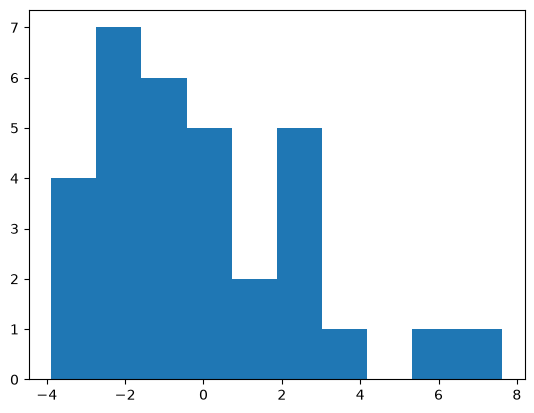

In [20]:
plt.hist(df['rating'] - predicts)

In [21]:
from sklearn.preprocessing import PolynomialFeatures

poly_transformer = PolynomialFeatures(degree=2, include_bias=False)

X_poly = poly_transformer.fit_transform(X)

model.fit(X_poly, y)

X.head()


,cloud_cover_low,cloud_cover_high
0,100.0,98.0
1,0.0,0.0
2,0.0,9.0
3,52.0,97.0
4,31.0,0.0


In [22]:
predicts = model.predict(X_poly)


RMSE = ((df['rating']-predicts)**2).mean()**0.5

print(RMSE)

print(predicts)

1.916863566486615
[ 0.01742196  4.98770961  6.46510117  1.55198789  3.03794597  6.13006638
  6.91020635  4.98770961  3.4669799   1.42405061  4.88622492  4.98770961
  3.01621207  4.98770961  9.43195238  4.88622492  4.98770961  8.97223307
 10.28808987  4.98770961  4.98770961  4.98770961  3.40184163  6.55524157
  4.65090986 10.44260214  4.98770961  4.88622492  3.154072    4.99836912
  2.982061    3.55459389]
